In [1]:
import numpy as np
from keras.utils import load_img, img_to_array
import matplotlib.pyplot as plt
import os

# task 1

In [2]:
np.random.seed(42)

In [3]:
index_categories = ['angel', 'apple', 'bat', 'cat', 'dog', 'dragon', 'hexagon', 'mmap', 'line', 'sun']

angel    = np.load('data/raw/full_numpy_bitmap_angel.npy')
apple    = np.load('data/raw/full_numpy_bitmap_apple.npy')
bat      = np.load('data/raw/full_numpy_bitmap_bat.npy')
cat      = np.load('data/raw/full_numpy_bitmap_cat.npy')
dog      = np.load('data/raw/full_numpy_bitmap_dog.npy')
dragon   = np.load('data/raw/full_numpy_bitmap_dragon.npy')
hexagon  = np.load('data/raw/full_numpy_bitmap_hexagon.npy')
line     = np.load('data/raw/full_numpy_bitmap_line.npy')
mmap     = np.load('data/raw/full_numpy_bitmap_map.npy')
sun      = np.load('data/raw/full_numpy_bitmap_sun.npy')


heldout_categories = ['triangle']
triangle = np.load('data/raw/full_numpy_bitmap_triangle.npy')



In [4]:
all_index = [angel, apple, bat, cat, dog, dragon, hexagon, mmap, line, sun]

gallery_images = []
gallery_labels = []
query_images = []
query_labels = []

for i in range(10):
    data = all_index[i]
    idx = np.random.choice(len(data), 500, replace=False)
    sample = data[idx]

    gallery_images.append(sample[:450])
    gallery_labels.append(np.full(450, i))
    query_images.append(sample[450:])
    query_labels.append(np.full(50, i))

gallery_images = np.concatenate(gallery_images)
gallery_labels = np.concatenate(gallery_labels)
query_images = np.concatenate(query_images)
query_labels = np.concatenate(query_labels)

In [5]:
idx = np.random.choice(len(triangle), 50, replace=False)
heldout_images = triangle[idx]
heldout_labels = np.full(50, 0)

In [6]:
np.savez('data/subset.npz',
         gallery_images=gallery_images,
         gallery_labels=gallery_labels,
         query_images=query_images,
         query_labels=query_labels,
         heldout_images=heldout_images,
         heldout_labels=heldout_labels,
         index_categories=index_categories,
         heldout_categories=heldout_categories)

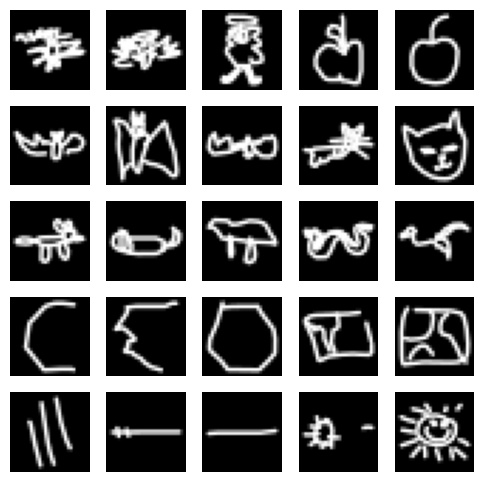

In [7]:
plt.figure(figsize=(6, 6))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(gallery_images[i * 180].reshape(28, 28, 1), cmap='gray')
    plt.axis('off')
plt.show()

# task 2

In [8]:
SIZE = 128

In [9]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics.pairwise import cosine_similarity

backbone = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(SIZE, SIZE, 3))
backbone.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [10]:
def embed(images_28):
    vectors = []

    for start in range(0, len(images_28), 64):
        batch = images_28[start:start + 64]

        batch = batch.reshape(-1, 28, 28, 1)           # flat 784 -> 28x28 picture with 1 channel
        batch = tf.image.resize(batch, (SIZE, SIZE))   # make them bigger
        batch = tf.image.grayscale_to_rgb(batch)       # 1 gray channel -> 3 channels
        batch = preprocess_input(batch.numpy())        # tensor -> numpy, then scale 0..255 to -1..1

        vectors.append(backbone.predict(batch, verbose=0))

    vectors = np.concatenate(vectors)
    lengths = np.linalg.norm(vectors, axis=1, keepdims=True)
    return vectors / lengths

In [11]:
gallery_vectors = embed(gallery_images)

os.makedirs('index', exist_ok=True)

np.save('index/embeddings.npy', gallery_vectors)
np.save('index/gallery_images.npy', gallery_images.reshape(-1, 28, 28))
np.save('index/gallery_labels.npy', gallery_labels)

# task 3

In [21]:
def preprocess_query(image):

    # Step 1: transparent background -> white, then make it gray
    image = image.convert("RGBA")
    white = Image.new("RGBA", image.size, "white")
    gray = np.array(Image.alpha_composite(white, image).convert("L"))

    # Step 2: dark pixels are the strokes (white on black, like the gallery)
    is_stroke = gray < gray.mean() - 40
    if is_stroke.sum() < 20:                  # nothing drawn -> no search
        return None
    strokes = Image.fromarray(np.where(is_stroke, 255, 0).astype("uint8"))

    # Step 3: cut away the empty space, then center the strokes in a square
    strokes = strokes.crop(strokes.getbbox())
    width, height = strokes.size
    side = int(max(width, height) * 1.25)        # 25% bigger = margin
    square = Image.new("L", (side, side), 0)
    square.paste(strokes, ((side - width) // 2, (side - height) // 2))

    # Step 4: thicker lines (bigger drawing = thicker), shrink to 28 x 28
    thick = side // 28 * 2 + 1
    square = square.filter(ImageFilter.MaxFilter(thick))
    small = np.array(square.resize((28, 28)))
    small = (small / small.max() * 255).astype("uint8")

    return small

# task 4

In [22]:
from sklearn.neighbors import NearestNeighbors

def search(query_vectors, embeddings, k):
    finder = NearestNeighbors(n_neighbors=k, metric='cosine')
    finder.fit(embeddings)
    distances, indices = finder.kneighbors(query_vectors)
    return indices, 1 - distances            # score = 1 - distance

def precision_at_k(query_vecs, gallery_vecs, k):
    indices, scores = search(query_vecs, gallery_vecs, k)
    found_labels = gallery_labels[indices]                    # category of each result
    correct = found_labels == query_labels.reshape(-1, 1)     # True if same category as the query
    return correct.mean(axis=1)                               # share of correct results per query

In [23]:
# model vectors
query_vectors = embed(query_images)
heldout_vectors = embed(heldout_images)

# raw-pixel vectors (baseline)
raw_gallery = gallery_images / np.linalg.norm(gallery_images, axis=1, keepdims=True)
raw_query = query_images / np.linalg.norm(query_images, axis=1, keepdims=True)

In [15]:
p5 = precision_at_k(query_vectors, gallery_vectors, 5)
p25 = precision_at_k(query_vectors, gallery_vectors, 25)

raw_p5 = precision_at_k(raw_query, raw_gallery, 5)
raw_p25 = precision_at_k(raw_query, raw_gallery, 25)

print("Method        p@5     p@25")
print("Raw pixels   ", round(raw_p5.mean(), 3), "  ", round(raw_p25.mean(), 3))
print("Your model   ", round(p5.mean(), 3), "  ", round(p25.mean(), 3))

Method        p@5     p@25
Raw pixels    0.566    0.525
Your model    0.765    0.715


In [16]:
#best score of every query
best_query = search(query_vectors, gallery_vectors, 1)[1].max(axis=1)       # 500 values
best_heldout = search(heldout_vectors, gallery_vectors, 1)[1].max(axis=1)   # 50 values

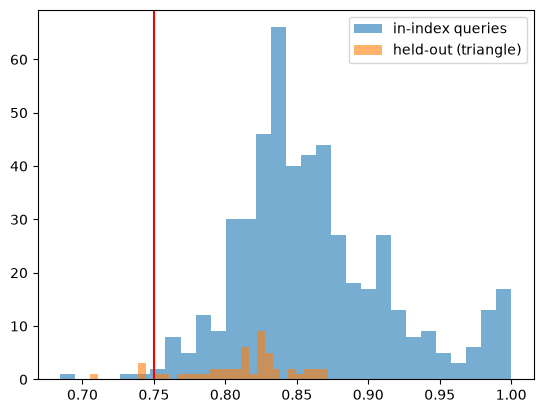

queries wrongly rejected: 3 of 500
triangles wrongly accepted: 46 of 50


In [17]:
threshold = 0.75


plt.hist(best_query, bins=30, alpha=0.6, label='in-index queries')
plt.hist(best_heldout, bins=30, alpha=0.6, label='held-out (triangle)')
plt.axvline(threshold, color='red')
plt.legend()
plt.show()

print("queries wrongly rejected:", (best_query < threshold).sum(), "of 500")
print("triangles wrongly accepted:", (best_heldout >= threshold).sum(), "of 50")

In [18]:
open('index/config.json', 'w').write('{"threshold": ' + str(threshold) + ', "top_k": 25}')

32

In [19]:
good = np.where(p5 == 1.0)[0][:3]       # all top 5 were right
bad = np.where(p5 == 0.0)[0][:3]        # none of the top 5 were right
picked = list(good) + list(bad)

top5 = search(query_vectors, gallery_vectors, 5)[0]

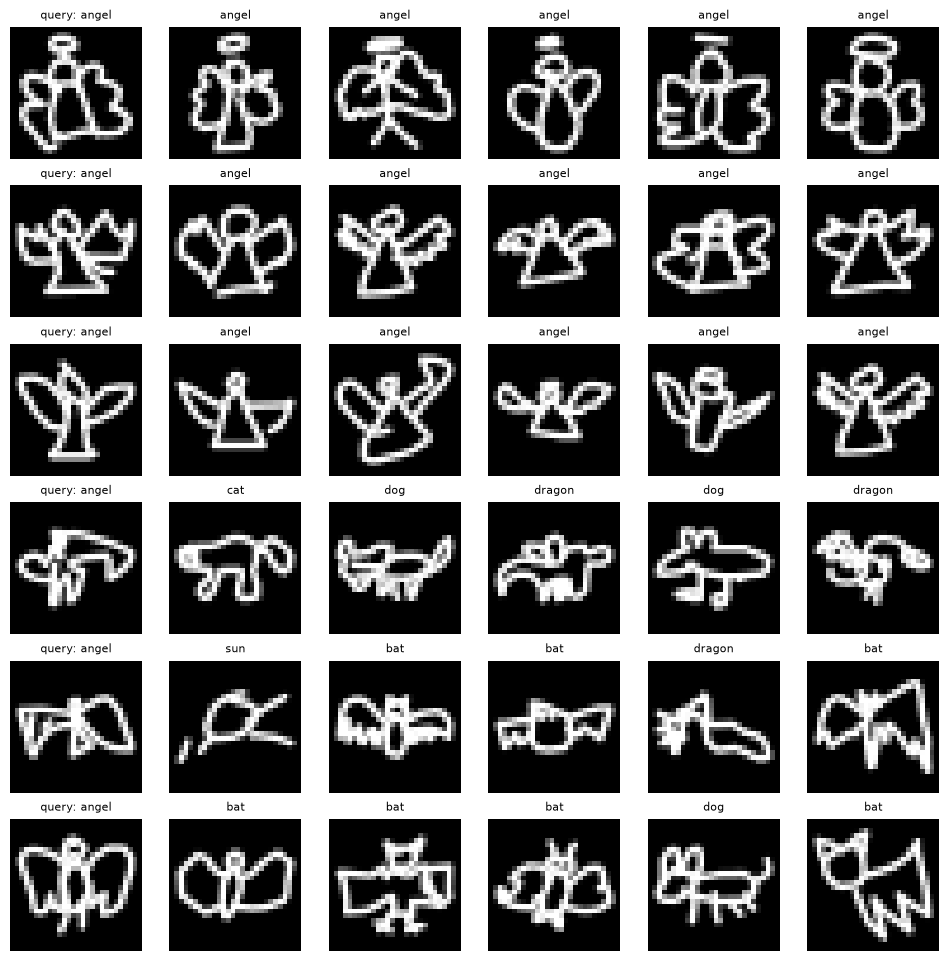

In [20]:
plt.figure(figsize=(12, 12))

for row in range(6):
    i = picked[row]

    # the query
    plt.subplot(6, 6, row * 6 + 1)
    plt.imshow(query_images[i].reshape(28, 28), cmap='gray')
    plt.title('query: ' + index_categories[query_labels[i]], fontsize=8)
    plt.axis('off')

    # its 5 results
    for j in range(5):
        plt.subplot(6, 6, row * 6 + j + 2)
        plt.imshow(gallery_images[top5[i][j]].reshape(28, 28), cmap='gray')
        plt.title(index_categories[gallery_labels[top5[i][j]]], fontsize=8)
        plt.axis('off')

plt.show()